# 🚗 Tunisian Car Listings — Exploratory Data Analysis

This notebook explores a unified dataset of used & new car listings scraped from
multiple Tunisian car marketplaces (`automobile.tn`, `baniola.tn`, `scoutcar.tn`,
`automax.tn`, `automoto.tn`, `zmorda.tn`, and a few "neuves" / new-car sources).

**What we'll do:**
1. Load & get an overview of the data
2. Check missing values
3. Check duplicates (exact rows, duplicate URLs, near-duplicate listings)
4. Clean & engineer a few useful columns (without destroying the raw data)
5. Detect outliers in `price_tnd` and `mileage_km`
6. Univariate exploration (makes, models, fuel type, transmission, body type, region, source...)
7. Bivariate/relationship exploration (price vs year, price vs mileage, price by fuel type, etc.)
8. A few creative/extra angles (price per km driven, market share by source, listing trends over time, price depreciation curve...)
9. Wrap-up summary of key findings


## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ----- Display / plotting defaults -----
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

sns.set_theme(style='whitegrid', palette='viridis')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

RANDOM_STATE = 42
DATA_PATH = 'unified_car_listings.csv'  # <-- change if needed


## 1. Load the data & first look

In [2]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()  # we work on a copy so df_raw always stays untouched

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Shape: 10,927 rows x 20 columns


,listing_id,source,title_raw,make,model,year,price_tnd,mileage_km,fuel_type,transmission,body_type,region,seller_type,listing_date,source_deal_label,condition,is_new,listing_url,is_price_outlier,is_mileage_outlier
0,automobile_tn_0,automobile_tn,Mercedes-Benz Classe C AMG,Mercedes-Benz,Classe C AMG,"2,015.00","75,000.00","220,000.00",Diesel,Automatic,Unknown,Tunis,Private,2026-06-15,Prix équitable,Used,False,https://www.automobile.tn/fr/occasion/mercedes...,False,False
1,automobile_tn_1,automobile_tn,Hyundai Grand i10 High Grade,Hyundai,Grand i10 High Grade,"2,022.00","42,000.00",128.00,Petrol,Manual,Unknown,Zaghouan,Private,2026-06-25,Très bon prix,Used,False,https://www.automobile.tn/fr/occasion/hyundai/...,False,False
2,automobile_tn_2,automobile_tn,Hyundai Grand i10 High Grade,Hyundai,Grand i10 High Grade,"2,022.00","48,000.00","24,000.00",Petrol,Manual,Unknown,Sfax,Private,2026-06-25,Prix équitable,Used,False,https://www.automobile.tn/fr/occasion/hyundai/...,False,False
3,automobile_tn_3,automobile_tn,Toyota RAV 4 Hybride,Toyota,RAV 4 Hybride,"2,025.00","157,000.00","18,000.00",Hybrid,Automatic,Unknown,Tunis,Private,2026-06-25,Bon prix,Used,False,https://www.automobile.tn/fr/occasion/toyota/r...,False,False
4,automobile_tn_4,automobile_tn,Mercedes-Benz CLA AMG Edition 1,Mercedes-Benz,CLA AMG Edition 1,"2,025.00","176,000.00","15,788.00",Hybrid,Automatic,Unknown,Ariana,Pro,2026-06-13,Prix élevé,Used,False,https://www.automobile.tn/fr/occasion/vendeurs...,False,False


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10927 entries, 0 to 10926
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   listing_id          10927 non-null  object 
 1   source              10927 non-null  object 
 2   title_raw           10927 non-null  object 
 3   make                10927 non-null  object 
 4   model               10927 non-null  object 
 5   year                9035 non-null   float64
 6   price_tnd           10510 non-null  float64
 7   mileage_km          10778 non-null  float64
 8   fuel_type           10927 non-null  object 
 9   transmission        10927 non-null  object 
 10  body_type           10927 non-null  object 
 11  region              10927 non-null  object 
 12  seller_type         10927 non-null  object 
 13  listing_date        8982 non-null   object 
 14  source_deal_label   8599 non-null   object 
 15  condition           10927 non-null  object 
 16  is_n

In [4]:
# Quick statistical summary of numeric columns
df.describe(include='number').T


,count,mean,std,min,25%,50%,75%,max
year,"9,035.00","2,015.89",6.69,"1,980.00","2,012.00","2,017.00","2,021.00","2,026.00"
price_tnd,"10,510.00","107,676.09","1,460,131.13",1.00,"33,000.00","49,350.00","83,000.00","98,225,724.00"
mileage_km,"10,778.00","144,655.10","255,714.17",0.00,"57,000.00","122,000.00","200,000.00","17,000,000.00"


In [5]:
# Quick summary of categorical / object columns
df.describe(include='object').T


,count,unique,top,freq
listing_id,10927,10927,automobile_tn_0,1
source,10927,9,scoutcar_tn,4127
title_raw,10927,6442,Peugeot 208,80
make,10927,83,Volkswagen,1213
model,10927,4131,Golf,300
fuel_type,10927,6,Petrol,7119
transmission,10927,4,Manual,4298
body_type,10927,21,Unknown,5994
region,10927,25,Tunis,2917
seller_type,10927,3,Unknown,7731


## 2. Missing values

Let's quantify missingness per column, both as counts and percentages, and visualize it.


In [6]:
missing = pd.DataFrame({
    'n_missing': df.isna().sum(),
    'pct_missing': (df.isna().mean() * 100).round(2)
}).sort_values('pct_missing', ascending=False)

missing[missing['n_missing'] > 0]


,n_missing,pct_missing
source_deal_label,2328,21.31
listing_date,1945,17.80
year,1892,17.31
price_tnd,417,3.82
mileage_km,149,1.36


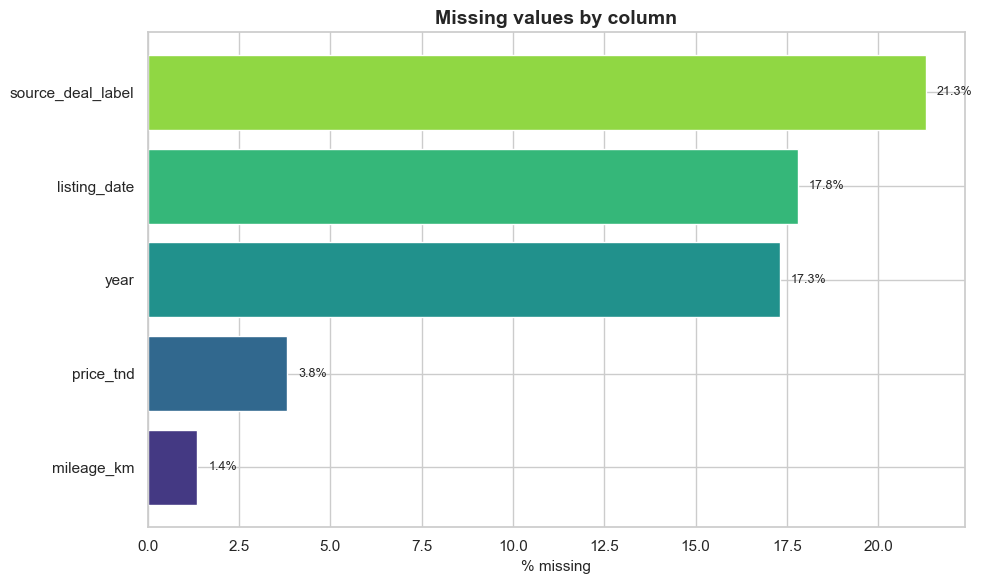

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
miss_plot = missing[missing['n_missing'] > 0].sort_values('pct_missing')
bars = ax.barh(miss_plot.index, miss_plot['pct_missing'], color=sns.color_palette('viridis', len(miss_plot)))
ax.set_xlabel('% missing')
ax.set_title('Missing values by column')
for bar, val in zip(bars, miss_plot['pct_missing']):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2, f'{val:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()


**Notes on missingness in this dataset:**
- `year`, `price_tnd`, `mileage_km` are the numeric fields most likely to have gaps — worth checking if missingness correlates with `source` (some sites may not always expose price/mileage).
- `listing_date` and `source_deal_label` have missing values too — `source_deal_label` is naturally missing for sources that don't provide a price-fairness label.


In [8]:
# Does missingness in price/mileage/year depend on the source website?
for col in ['price_tnd', 'mileage_km', 'year']:
    print(f"--- % missing '{col}' by source ---")
    print((df.groupby('source')[col].apply(lambda s: s.isna().mean()*100)).round(1).sort_values(ascending=False))
    print()


--- % missing 'price_tnd' by source ---
source
zmorda_tn              13.20
baniola_tn             11.80
sayarti_tn_neuves       3.80
automax_tn              0.50
automobile_tn           0.00
automobile_tn_neuves    0.00
automoto_tn             0.00
autoplus_tn_neuves      0.00
scoutcar_tn             0.00
Name: price_tnd, dtype: float64

--- % missing 'mileage_km' by source ---
source
baniola_tn             6.10
automax_tn             0.00
automobile_tn          0.00
automobile_tn_neuves   0.00
automoto_tn            0.00
autoplus_tn_neuves     0.00
sayarti_tn_neuves      0.00
scoutcar_tn            0.00
zmorda_tn              0.00
Name: mileage_km, dtype: float64

--- % missing 'year' by source ---
source
automobile_tn_neuves   100.00
autoplus_tn_neuves     100.00
sayarti_tn_neuves      100.00
zmorda_tn              100.00
baniola_tn               1.10
automax_tn               0.30
automobile_tn            0.00
automoto_tn              0.00
scoutcar_tn              0.00
Name: year, d

## 3. Duplicates

We check duplicates at a few different levels of strictness:
1. **Fully identical rows**
2. **Duplicate `listing_id`** (should never happen if it's a proper primary key)
3. **Duplicate `listing_url`** (same ad posted/scraped more than once)
4. **Near-duplicate listings**: same make, model, year, price, mileage, region — i.e. probably the same car, possibly re-listed or cross-posted on a different source


In [9]:
n_full_dupes = df.duplicated().sum()
n_id_dupes = df.duplicated(subset=['listing_id']).sum()
n_url_dupes = df.duplicated(subset=['listing_url']).sum()

near_dupe_cols = ['make', 'model', 'year', 'price_tnd', 'mileage_km', 'region']
n_near_dupes = df.duplicated(subset=near_dupe_cols).sum()

print(f"Fully identical rows        : {n_full_dupes:,}")
print(f"Duplicate listing_id        : {n_id_dupes:,}")
print(f"Duplicate listing_url       : {n_url_dupes:,}")
print(f"Near-duplicate listings*    : {n_near_dupes:,}  (*same make/model/year/price/mileage/region)")


Fully identical rows        : 0
Duplicate listing_id        : 0
Duplicate listing_url       : 1,151
Near-duplicate listings*    : 396  (*same make/model/year/price/mileage/region)


In [10]:
# Inspect a sample of duplicate URLs - are these the same listing scraped twice (maybe by different sources)?
dupe_urls = df[df.duplicated(subset=['listing_url'], keep=False)].sort_values('listing_url')
dupe_urls[['listing_id', 'source', 'listing_url', 'make', 'model', 'price_tnd']].head(10)


,listing_id,source,listing_url,make,model,price_tnd
7081,scoutcar_tn_32246,scoutcar_tn,False,Opel,Combo,"46,000.00"
5412,scoutcar_tn_59766,scoutcar_tn,False,Peugeot,Landtrek Simple Cabine,"60,000.00"
5464,scoutcar_tn_58740,scoutcar_tn,False,Fiat,500,"27,000.00"
5751,scoutcar_tn_53630,scoutcar_tn,False,Peugeot,208,"34,000.00"
5754,scoutcar_tn_53617,scoutcar_tn,False,Peugeot,206,"20,000.00"
5859,scoutcar_tn_51550,scoutcar_tn,False,Fiat,Punto,"13,500.00"
5940,scoutcar_tn_49673,scoutcar_tn,False,Opel,Astra,"20,500.00"
6039,scoutcar_tn_48126,scoutcar_tn,False,Volkswagen,Tiguan R,"90,000.00"
6061,scoutcar_tn_47798,scoutcar_tn,False,Kia,Rio,"50,000.00"
6134,scoutcar_tn_46449,scoutcar_tn,False,Citroen,C3,"26,000.00"


In [11]:
# Inspect near-duplicates: likely the same car cross-listed on multiple platforms
near_dupes = df[df.duplicated(subset=near_dupe_cols, keep=False)].sort_values(near_dupe_cols)
near_dupes[['source', 'make', 'model', 'year', 'price_tnd', 'mileage_km', 'region']].head(10)


,source,make,model,year,price_tnd,mileage_km,region
10113,automobile_tn_neuves,Audi,A3 Berline,NaN,"149,990.00",0.00,Unknown
10257,autoplus_tn_neuves,Audi,A3 Berline,NaN,"149,990.00",0.00,Unknown
10092,automobile_tn_neuves,Audi,A3 Sportback,NaN,"129,990.00",0.00,Unknown
10255,autoplus_tn_neuves,Audi,A3 Sportback,NaN,"129,990.00",0.00,Unknown
8934,automoto_tn,Audi,A4,"2,002.00","24,000.00","120,000.00",Nabeul
8935,automoto_tn,Audi,A4,"2,002.00","24,000.00","120,000.00",Nabeul
10165,automobile_tn_neuves,Audi,A5,NaN,"219,990.00",0.00,Unknown
10259,autoplus_tn_neuves,Audi,A5,NaN,"219,990.00",0.00,Unknown
4651,scoutcar_tn,Audi,Q2,"2,018.00","71,000.00","60,000.00",Tunis
8516,automax_tn,Audi,Q2,"2,018.00","71,000.00","60,000.00",Tunis


**Decision:** we keep `df_raw`/`df` untouched for now and create a de-duplicated version
`df_dedup` (dropping duplicate `listing_url`, keeping the first occurrence) that we'll use
for some of the "market" visualisations later, so a single car cross-posted on 3 sites
doesn't get counted 3 times. For most other plots we keep every row, since re-listings can
also be legitimate (price drop, relist after time on the market, etc.).


In [12]:
df_dedup = df.drop_duplicates(subset=['listing_url']).copy()
print(f"Rows before de-dup: {len(df):,}  |  after de-dup on listing_url: {len(df_dedup):,}  "
      f"({len(df) - len(df_dedup):,} removed)")


Rows before de-dup: 10,927  |  after de-dup on listing_url: 9,776  (1,151 removed)


## 4. Light cleaning & feature engineering

We don't want to destroy the raw data, so all cleaning below creates a new working
dataframe `dfc` with a few helper columns:

- `listing_date` → proper `datetime`
- `car_age` → `listing year - model year` (a more intuitive feature than raw `year`)
- `price_per_km` → crude "value" proxy for used cars (price / (mileage+1))
- Basic sanity flags for impossible values (price/mileage == 0 or absurdly large)


In [13]:
dfc = df.copy()

# --- Parse dates ---
dfc['listing_date'] = pd.to_datetime(dfc['listing_date'], errors='coerce')

# --- Car age (only meaningful for used cars with a valid year) ---
current_year = dfc['listing_date'].dt.year.max()
current_year = int(current_year) if pd.notna(current_year) else pd.Timestamp.today().year
dfc['car_age'] = current_year - dfc['year']
dfc.loc[dfc['car_age'] < 0, 'car_age'] = np.nan  # guard against bad/future years

# --- Price per km driven (avoid div-by-zero) ---
dfc['price_per_km'] = dfc['price_tnd'] / (dfc['mileage_km'] + 1)

# --- Sanity flags (in addition to the dataset's own is_price_outlier / is_mileage_outlier) ---
dfc['price_is_zero_or_neg'] = dfc['price_tnd'] <= 0
dfc['mileage_is_zero'] = dfc['mileage_km'] == 0

print("New columns added:", ['listing_date (datetime)', 'car_age', 'price_per_km',
                              'price_is_zero_or_neg', 'mileage_is_zero'])
dfc[['make', 'model', 'year', 'car_age', 'price_tnd', 'mileage_km', 'price_per_km']].head()


New columns added: ['listing_date (datetime)', 'car_age', 'price_per_km', 'price_is_zero_or_neg', 'mileage_is_zero']


,make,model,year,car_age,price_tnd,mileage_km,price_per_km
0,Mercedes-Benz,Classe C AMG,"2,015.00",11.00,"75,000.00","220,000.00",0.34
1,Hyundai,Grand i10 High Grade,"2,022.00",4.00,"42,000.00",128.00,325.58
2,Hyundai,Grand i10 High Grade,"2,022.00",4.00,"48,000.00","24,000.00",2.00
3,Toyota,RAV 4 Hybride,"2,025.00",1.00,"157,000.00","18,000.00",8.72
4,Mercedes-Benz,CLA AMG Edition 1,"2,025.00",1.00,"176,000.00","15,788.00",11.15


## 5. Outlier detection

The dataset already ships with two boolean flags — `is_price_outlier` and
`is_mileage_outlier` — presumably computed upstream. Let's first see how many rows they
flag, then **independently** verify with our own IQR-based method to see whether we
agree, and finally look at the extreme values directly.


In [14]:
print("Existing flags in the data:")
print(f"  is_price_outlier   : {dfc['is_price_outlier'].sum():,} rows ({dfc['is_price_outlier'].mean()*100:.1f}%)")
print(f"  is_mileage_outlier : {dfc['is_mileage_outlier'].sum():,} rows ({dfc['is_mileage_outlier'].mean()*100:.1f}%)")


Existing flags in the data:
  is_price_outlier   : 60 rows (0.5%)
  is_mileage_outlier : 71 rows (0.6%)


In [15]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

for col in ['price_tnd', 'mileage_km']:
    lo, hi = iqr_bounds(dfc[col].dropna())
    n_out = ((dfc[col] < lo) | (dfc[col] > hi)).sum()
    print(f"{col}: IQR bounds = [{lo:,.0f}, {hi:,.0f}]  ->  {n_out:,} rows outside "
          f"({n_out/dfc[col].notna().sum()*100:.1f}% of non-null values)")


price_tnd: IQR bounds = [-42,000, 158,000]  ->  805 rows outside (7.7% of non-null values)
mileage_km: IQR bounds = [-157,500, 414,500]  ->  217 rows outside (2.0% of non-null values)


In [16]:
# The most extreme price & mileage listings - are these data errors or genuinely luxury/high-mileage cars?
print("Top 10 highest prices:")
display_cols = ['source', 'make', 'model', 'year', 'price_tnd', 'mileage_km', 'is_price_outlier']
print(dfc.nlargest(10, 'price_tnd')[display_cols].to_string(index=False))


Top 10 highest prices:
     source       make                  model     year     price_tnd  mileage_km  is_price_outlier
 baniola_tn Volkswagen       Golf 2010 328 Km 2,010.00 98,225,724.00      328.00              True
 automax_tn       SEAT                   Leon      NaN 52,149,505.00   80,000.00              True
 baniola_tn   DongFeng      Sx3 2022 65000 Km 2,022.00 48,000,000.00   56,000.00              True
  zmorda_tn    Citroen              C4 Cactus      NaN 48,000,000.00   71,524.00              True
 baniola_tn      Isuzu           Super Faster 1,998.00 45,000,000.00  369,000.00              True
 baniola_tn    Hyundai     I10 2021 276000 Km 2,021.00 36,000,000.00  276,000.00              True
 automax_tn    Peugeot                    208 2,014.00 35,000,000.00  270,000.00              True
 baniola_tn      Isuzu 10Ch 4 Portes 99184723 2,022.00 30,000,000.00         NaN              True
automoto_tn    Citroen                     LN 2,024.00  2,000,000.00   20,000.00      

In [17]:
print("Top 10 highest mileages:")
print(dfc.nlargest(10, 'mileage_km')[display_cols].to_string(index=False))


Top 10 highest mileages:
     source          make                  model     year  price_tnd    mileage_km  is_price_outlier
 baniola_tn         Mazda   Mazda6 2014 17000 Km 2,014.00  40,000.00 17,000,000.00             False
scoutcar_tn        Lancia                Ypsilon 2,016.00  28,000.00 11,111,111.00             False
 baniola_tn       Peugeot                    505 1,993.00        NaN  9,999,999.00             False
 baniola_tn Mercedes-Benz Classe C 2008 38000 Km 2,008.00  35,000.00  3,800,000.00             False
automoto_tn         Dacia                Sandero 2,009.00 170,000.00  3,200,000.00             False
 baniola_tn       Renault    Laguna 2004 3000 Km 2,004.00  16,000.00  3,000,000.00             False
 baniola_tn           BMW      318 2007 27000 Km 2,007.00  32,000.00  2,700,000.00             False
 baniola_tn       Renault          Symbol à Sfax 2,011.00  22,000.00  2,200,000.00             False
 baniola_tn    Mitsubishi    Autres 2015 2000 Km 2,015.00  33,000.

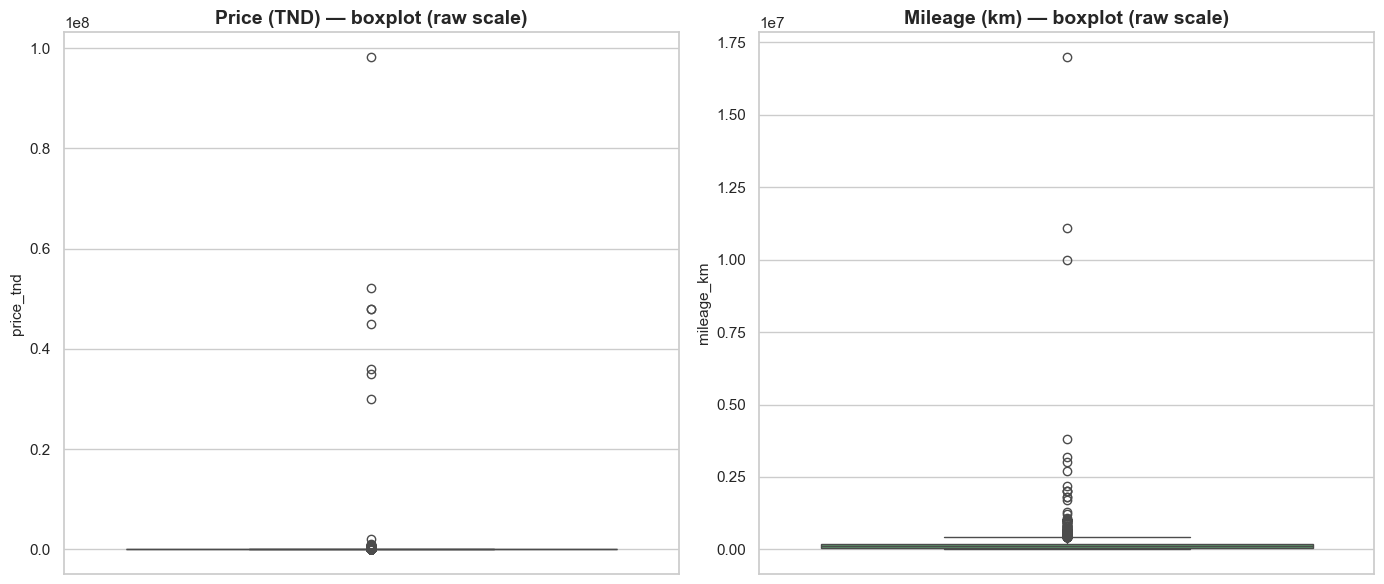

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(y=dfc['price_tnd'], ax=axes[0], color='#4C72B0')
axes[0].set_title('Price (TND) — boxplot (raw scale)')
axes[0].set_ylabel('price_tnd')

sns.boxplot(y=dfc['mileage_km'], ax=axes[1], color='#55A868')
axes[1].set_title('Mileage (km) — boxplot (raw scale)')
axes[1].set_ylabel('mileage_km')

plt.tight_layout()
plt.show()


The raw-scale boxplots are dominated by a handful of extreme values (likely data-entry
errors, e.g. a price in millions of TND, or mileage in the tens of millions of km — Tunisia's
whole road network isn't that long!). Let's log-transform to see the *real* shape of the
distribution, and define a **sensible working range** for visuals further down.


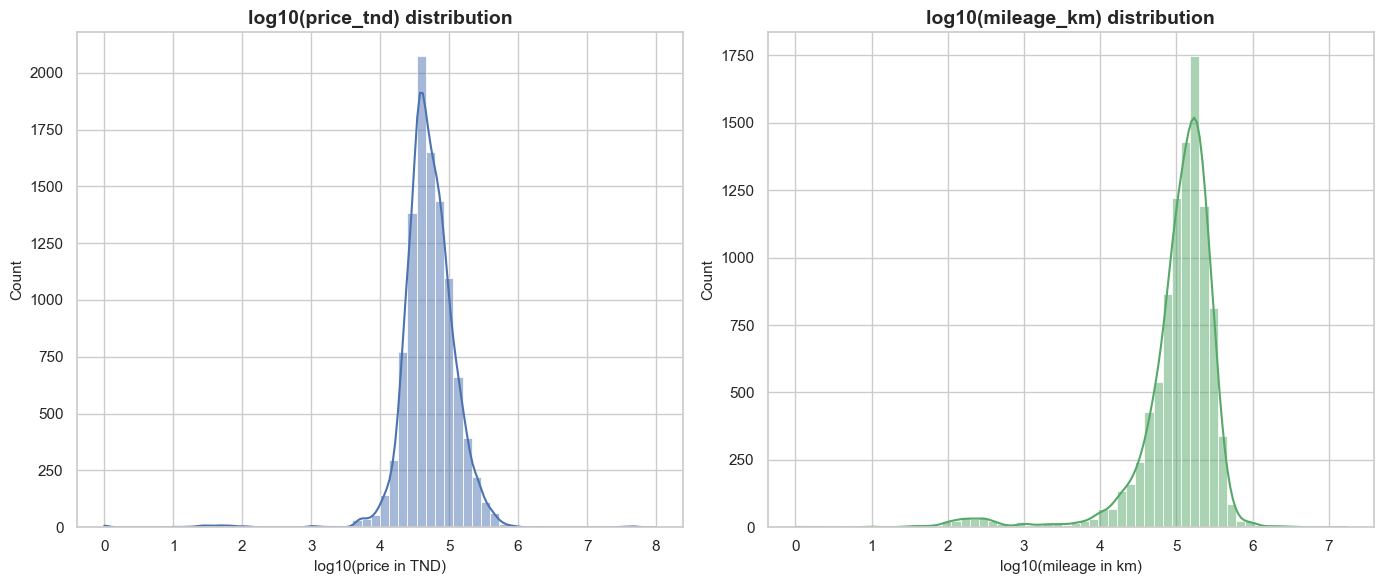

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.histplot(np.log10(dfc.loc[dfc['price_tnd'] > 0, 'price_tnd']), bins=60, ax=axes[0], color='#4C72B0', kde=True)
axes[0].set_title('log10(price_tnd) distribution')
axes[0].set_xlabel('log10(price in TND)')

sns.histplot(np.log10(dfc.loc[dfc['mileage_km'] > 0, 'mileage_km']), bins=60, ax=axes[1], color='#55A868', kde=True)
axes[1].set_title('log10(mileage_km) distribution')
axes[1].set_xlabel('log10(mileage in km)')

plt.tight_layout()
plt.show()


In [20]:
# Define a plausible working range for the Tunisian used-car market to use in later plots.
# (Reasonable used-car prices: a few thousand TND up to ~ a few hundred thousand TND;
#  reasonable mileage: 0 to ~500,000 km). Rows outside this are kept in the data
# but excluded from price/mileage-sensitive plots to avoid extreme values crushing the scale.
PRICE_MIN, PRICE_MAX = 1_000, 900_000
MILEAGE_MAX = 900_000

clean_price_mask = dfc['price_tnd'].between(PRICE_MIN, PRICE_MAX)
clean_mileage_mask = dfc['mileage_km'].between(0, MILEAGE_MAX)

n_price_excluded = (~clean_price_mask).sum()
n_mileage_excluded = (~clean_mileage_mask).sum()
print(f"Rows outside plausible price range [{PRICE_MIN:,}, {PRICE_MAX:,}] TND: {n_price_excluded:,}")
print(f"Rows outside plausible mileage range [0, {MILEAGE_MAX:,}] km: {n_mileage_excluded:,}")

dfv = dfc[clean_price_mask & clean_mileage_mask].copy()  # 'v' for 'viz-ready'
print(f"\nRows kept for price/mileage-sensitive visuals: {len(dfv):,} / {len(dfc):,} "
      f"({len(dfv)/len(dfc)*100:.1f}%)")


Rows outside plausible price range [1,000, 900,000] TND: 479
Rows outside plausible mileage range [0, 900,000] km: 184

Rows kept for price/mileage-sensitive visuals: 10,312 / 10,927 (94.4%)


## 6. Univariate exploration

### 6.1 Which makes dominate the market?

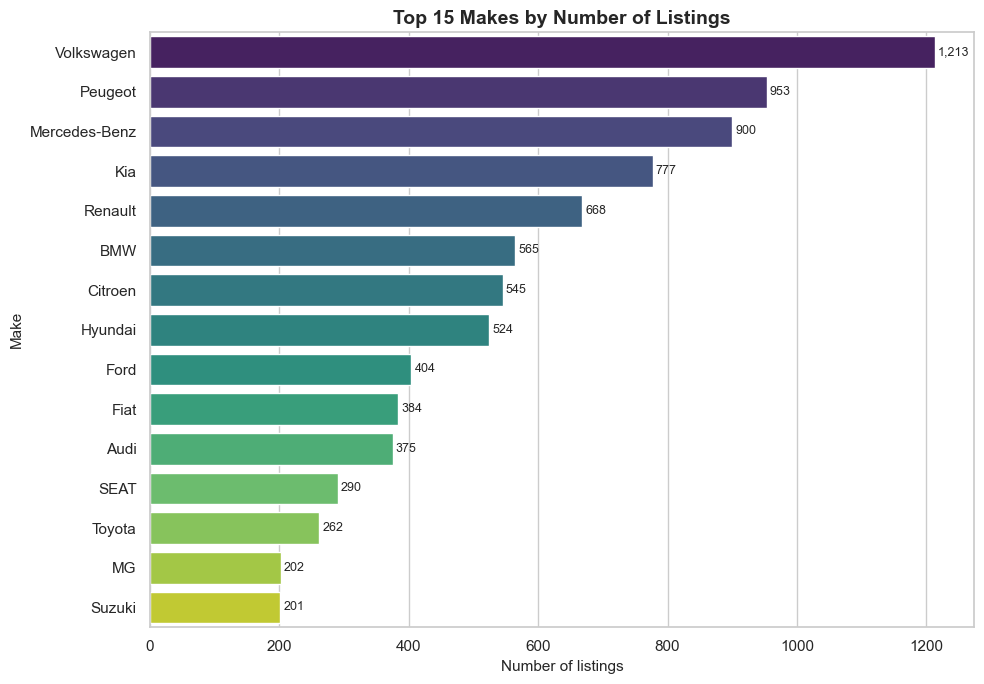

In [21]:
top_n = 15
make_counts = dfc['make'].value_counts().head(top_n)

plt.figure(figsize=(10, 7))
ax = sns.barplot(x=make_counts.values, y=make_counts.index, hue=make_counts.index,
                  palette='viridis', legend=False)
ax.set_title(f'Top {top_n} Makes by Number of Listings')
ax.set_xlabel('Number of listings')
ax.set_ylabel('Make')
for i, v in enumerate(make_counts.values):
    ax.text(v + 5, i, f'{v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()


### 6.2 Most listed models overall (make + model)

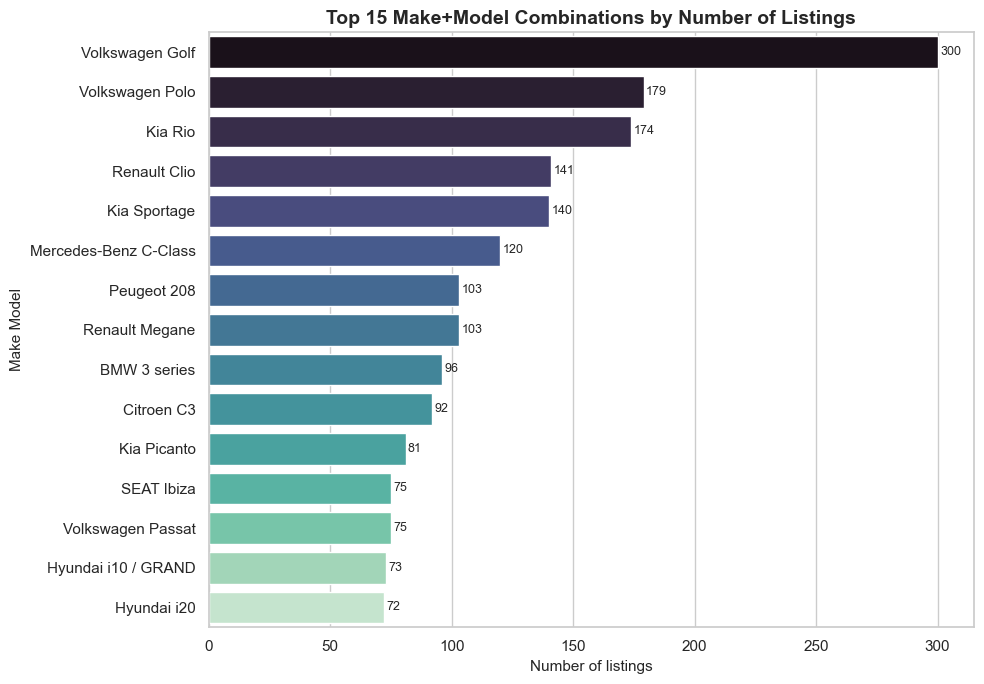

In [22]:
dfc['make_model'] = dfc['make'] + ' ' + dfc['model'].astype(str)
top_models = dfc['make_model'].value_counts().head(15)

plt.figure(figsize=(10, 7))
ax = sns.barplot(x=top_models.values, y=top_models.index, hue=top_models.index,
                  palette='mako', legend=False)
ax.set_title('Top 15 Make+Model Combinations by Number of Listings')
ax.set_xlabel('Number of listings')
ax.set_ylabel('Make Model')
for i, v in enumerate(top_models.values):
    ax.text(v + 1, i, f'{v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()


### 6.3 Top models *within* each of the top 5 makes (small multiples)

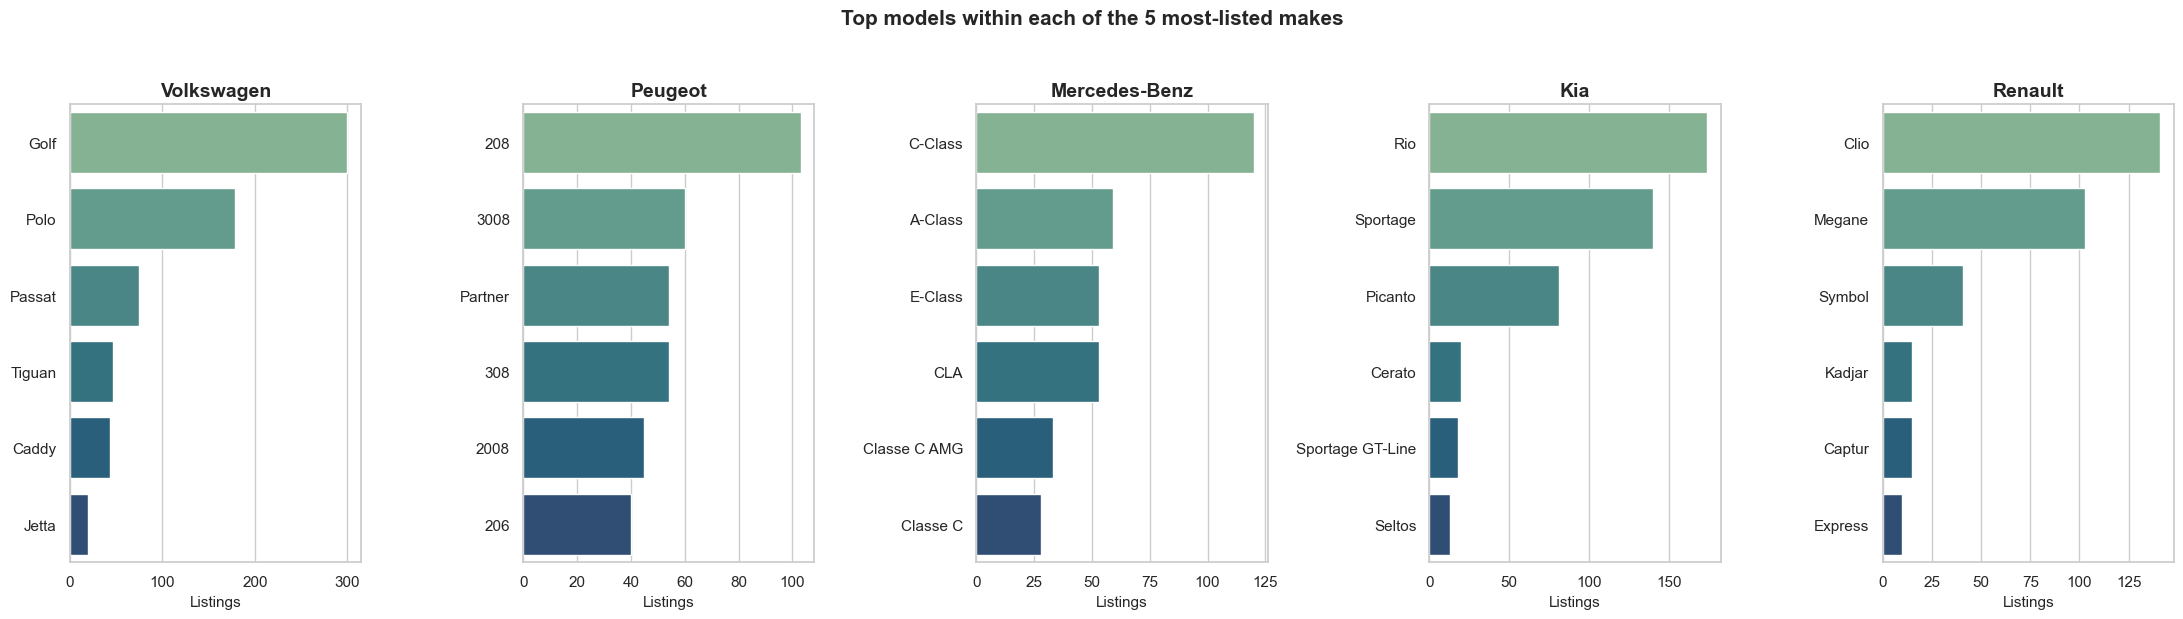

In [23]:
top5_makes = dfc['make'].value_counts().head(5).index.tolist()

fig, axes = plt.subplots(1, 5, figsize=(22, 6), sharey=False)
for ax, mk in zip(axes, top5_makes):
    sub = dfc.loc[dfc['make'] == mk, 'model'].value_counts().head(6)
    sns.barplot(x=sub.values, y=sub.index, ax=ax, hue=sub.index, palette='crest', legend=False)
    ax.set_title(mk)
    ax.set_xlabel('Listings')
    ax.set_ylabel('')
plt.suptitle('Top models within each of the 5 most-listed makes', y=1.03, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


### 6.4 Categorical breakdowns: fuel type, transmission, body type, seller type, condition

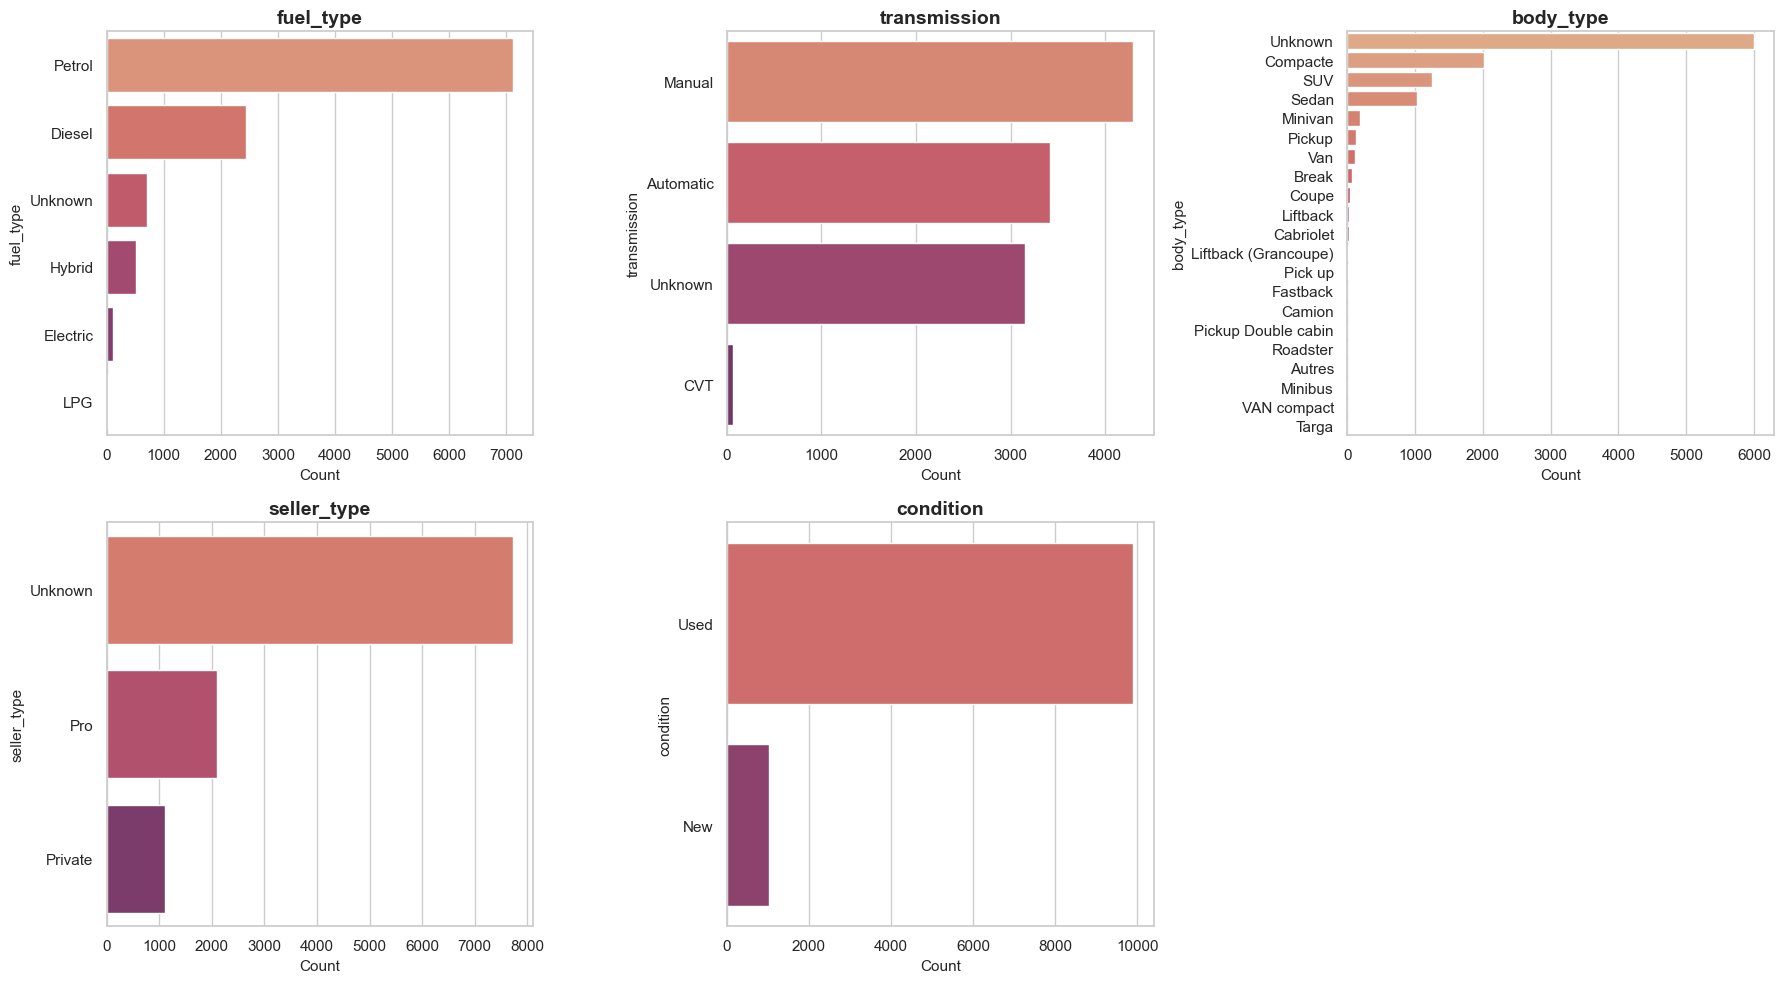

In [24]:
cat_cols = ['fuel_type', 'transmission', 'body_type', 'seller_type', 'condition']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for ax, col in zip(axes, cat_cols):
    counts = dfc[col].value_counts()
    sns.barplot(x=counts.values, y=counts.index, ax=ax, hue=counts.index, palette='flare', legend=False)
    ax.set_title(col)
    ax.set_xlabel('Count')
axes[-1].axis('off')  # spare subplot
plt.tight_layout()
plt.show()


### 6.5 Listings by region

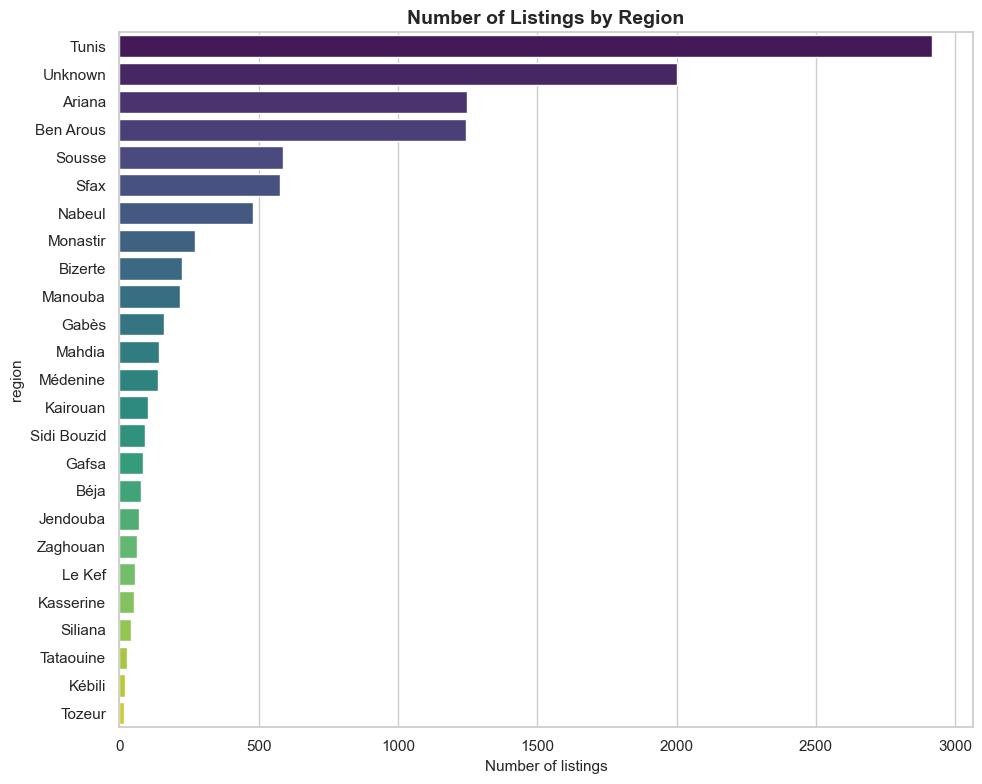

In [25]:
region_counts = dfc['region'].value_counts()

plt.figure(figsize=(10, 8))
ax = sns.barplot(x=region_counts.values, y=region_counts.index, hue=region_counts.index,
                  palette='viridis', legend=False)
ax.set_title('Number of Listings by Region')
ax.set_xlabel('Number of listings')
plt.tight_layout()
plt.show()


### 6.6 Listings by source (marketplace)

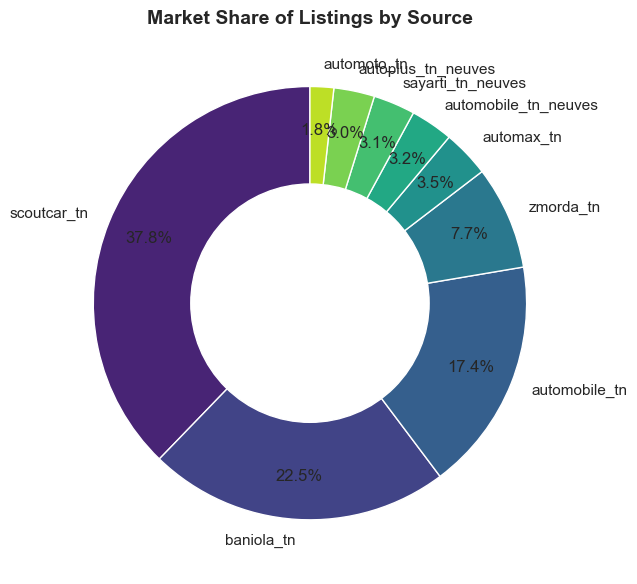

In [26]:
source_counts = dfc['source'].value_counts()

plt.figure(figsize=(9, 6))
colors = sns.color_palette('viridis', len(source_counts))
plt.pie(source_counts.values, labels=source_counts.index, autopct='%1.1f%%',
        colors=colors, startangle=90, pctdistance=0.8,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1})
centre_circle = plt.Circle((0, 0), 0.55, fc='white')
plt.gca().add_artist(centre_circle)
plt.title('Market Share of Listings by Source')
plt.tight_layout()
plt.show()


### 6.7 Price & mileage distributions (cleaned range)

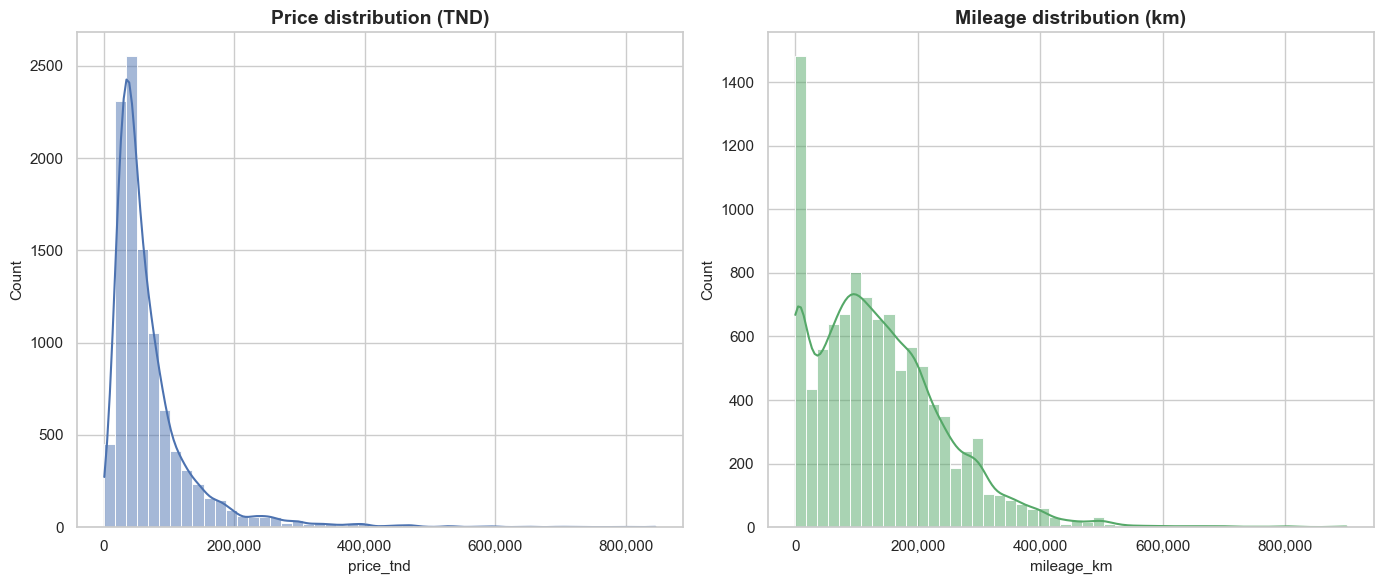

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.histplot(dfv['price_tnd'], bins=50, ax=axes[0], color='#4C72B0', kde=True)
axes[0].set_title('Price distribution (TND)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

sns.histplot(dfv['mileage_km'], bins=50, ax=axes[1], color='#55A868', kde=True)
axes[1].set_title('Mileage distribution (km)')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.tight_layout()
plt.show()


### 6.8 Model-year distribution — how old are the cars on the market?

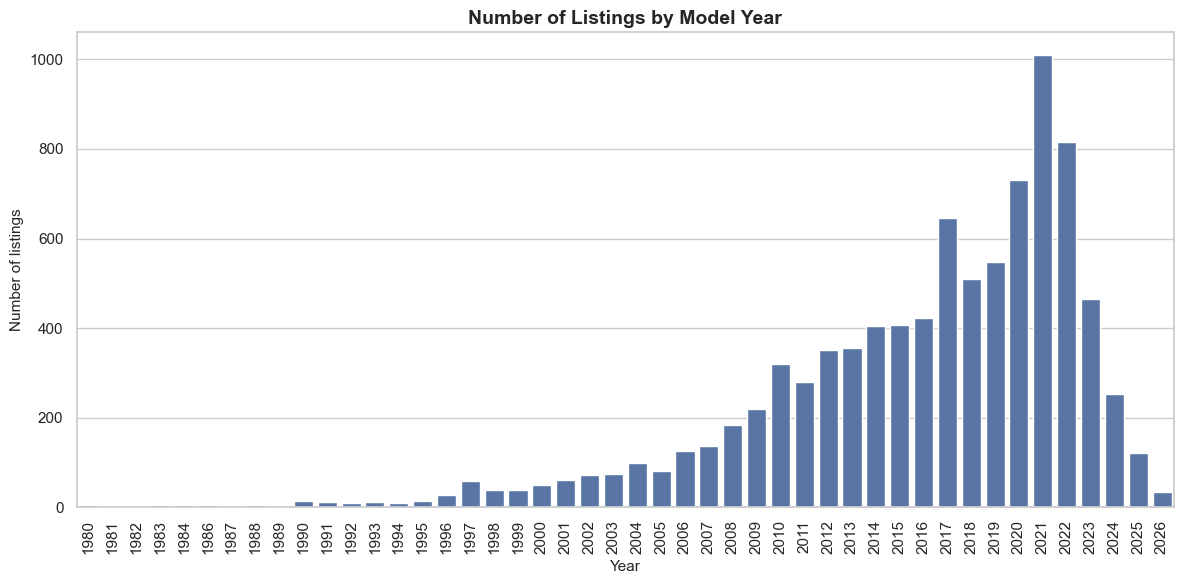

In [28]:
plt.figure(figsize=(12, 6))
year_counts = dfc['year'].value_counts().sort_index()
sns.barplot(x=year_counts.index.astype(int), y=year_counts.values, color='#4C72B0')
plt.xticks(rotation=90)
plt.title('Number of Listings by Model Year')
plt.xlabel('Year')
plt.ylabel('Number of listings')
plt.tight_layout()
plt.show()


## 7. Bivariate / relationship exploration

### 7.1 Price vs. car age

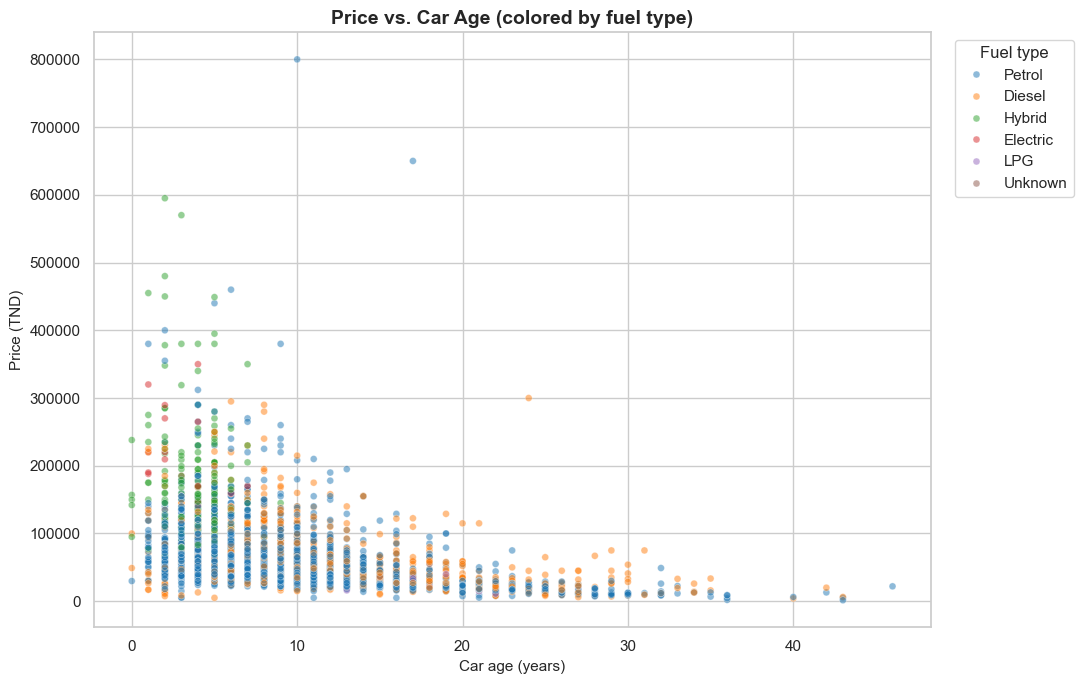

In [29]:
plt.figure(figsize=(11, 7))
sample_scatter = dfv.dropna(subset=['car_age', 'price_tnd'])
if len(sample_scatter) > 4000:
    sample_scatter = sample_scatter.sample(4000, random_state=RANDOM_STATE)
sns.scatterplot(data=sample_scatter, x='car_age', y='price_tnd', hue='fuel_type',
                 alpha=0.5, palette='tab10', s=25)
plt.title('Price vs. Car Age (colored by fuel type)')
plt.xlabel('Car age (years)')
plt.ylabel('Price (TND)')
plt.legend(title='Fuel type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 7.2 Price vs. mileage

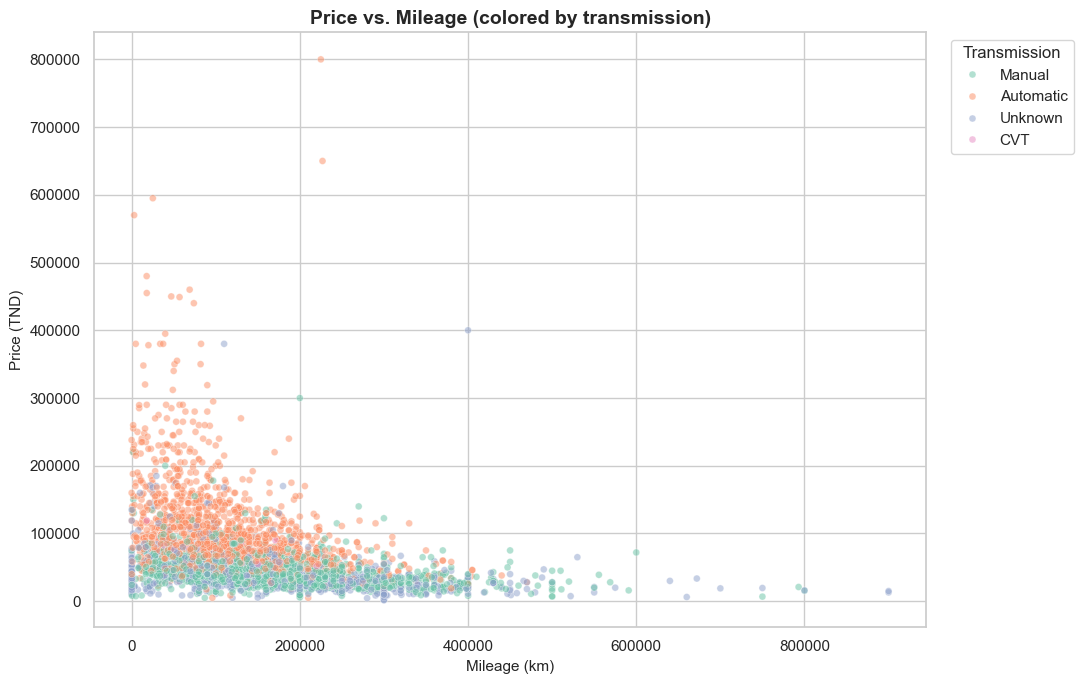

In [30]:
plt.figure(figsize=(11, 7))
sns.scatterplot(data=sample_scatter, x='mileage_km', y='price_tnd', hue='transmission',
                 alpha=0.5, palette='Set2', s=25)
plt.title('Price vs. Mileage (colored by transmission)')
plt.xlabel('Mileage (km)')
plt.ylabel('Price (TND)')
plt.legend(title='Transmission', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 7.3 Median price by make (top 15 by volume)

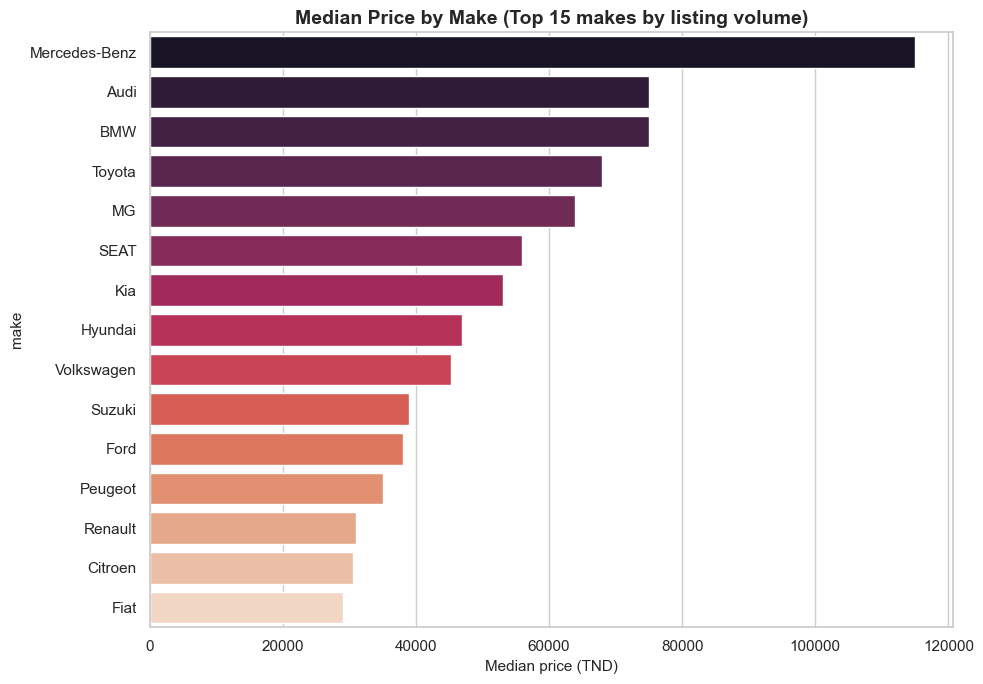

In [31]:
top15_makes = dfc['make'].value_counts().head(15).index
price_by_make = (dfv[dfv['make'].isin(top15_makes)]
                  .groupby('make')['price_tnd'].median()
                  .sort_values(ascending=False))

plt.figure(figsize=(10, 7))
ax = sns.barplot(x=price_by_make.values, y=price_by_make.index, hue=price_by_make.index,
                  palette='rocket', legend=False)
ax.set_title('Median Price by Make (Top 15 makes by listing volume)')
ax.set_xlabel('Median price (TND)')
plt.tight_layout()
plt.show()


### 7.4 Price distribution by fuel type

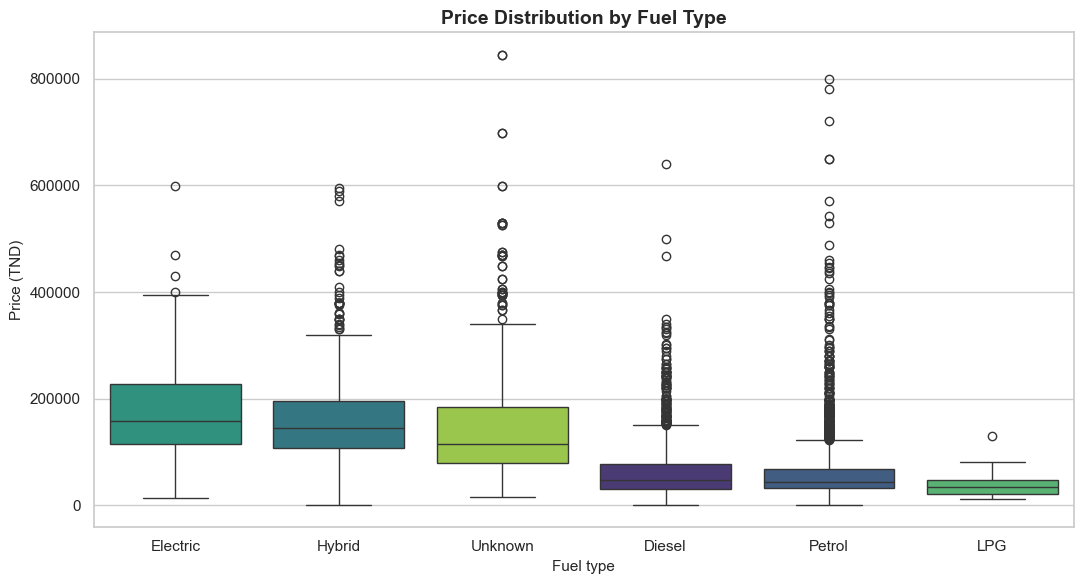

In [32]:
plt.figure(figsize=(11, 6))
order = dfv.groupby('fuel_type')['price_tnd'].median().sort_values(ascending=False).index
sns.boxplot(data=dfv, x='fuel_type', y='price_tnd', order=order, hue='fuel_type',
            palette='viridis', legend=False)
plt.title('Price Distribution by Fuel Type')
plt.xlabel('Fuel type')
plt.ylabel('Price (TND)')
plt.tight_layout()
plt.show()


### 7.5 Price by transmission & body type (heatmap of median price)

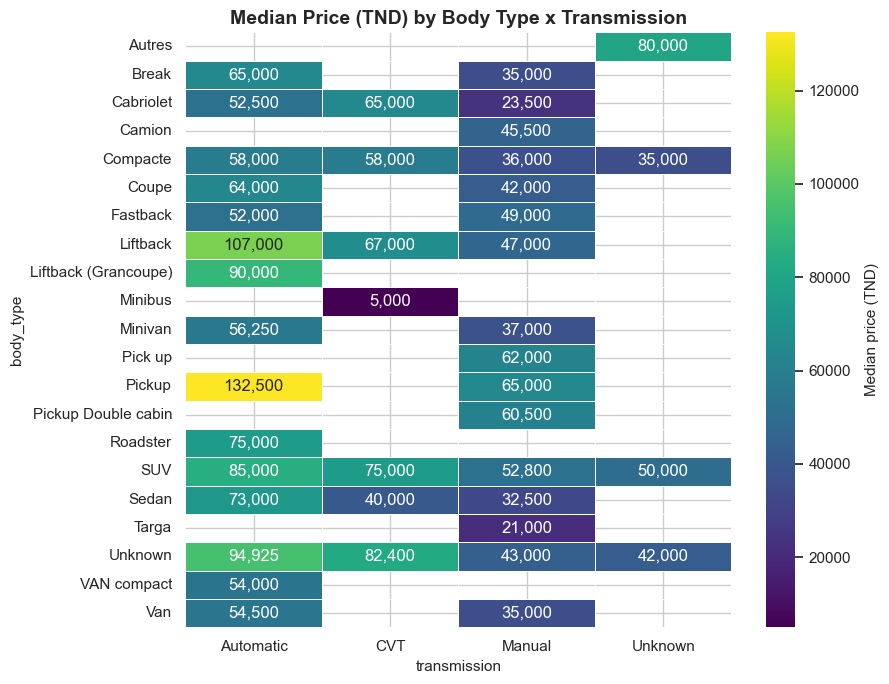

In [33]:
pivot = dfv.pivot_table(index='body_type', columns='transmission', values='price_tnd', aggfunc='median')
plt.figure(figsize=(9, 7))
sns.heatmap(pivot, annot=True, fmt=',.0f', cmap='viridis', linewidths=0.5, cbar_kws={'label': 'Median price (TND)'})
plt.title('Median Price (TND) by Body Type x Transmission')
plt.tight_layout()
plt.show()


### 7.6 Correlation heatmap of numeric features

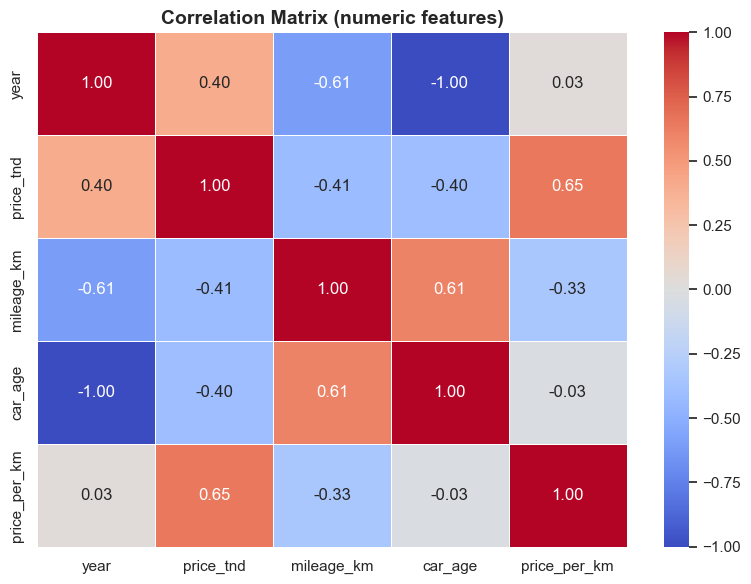

In [34]:
num_cols = ['year', 'price_tnd', 'mileage_km', 'car_age', 'price_per_km']
corr = dfv[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix (numeric features)')
plt.tight_layout()
plt.show()


## 8. Creative / extra angles

### 8.1 Depreciation curve: median price by car age (with volume overlay)

A classic used-car-market question: how fast does value drop off as a car ages?


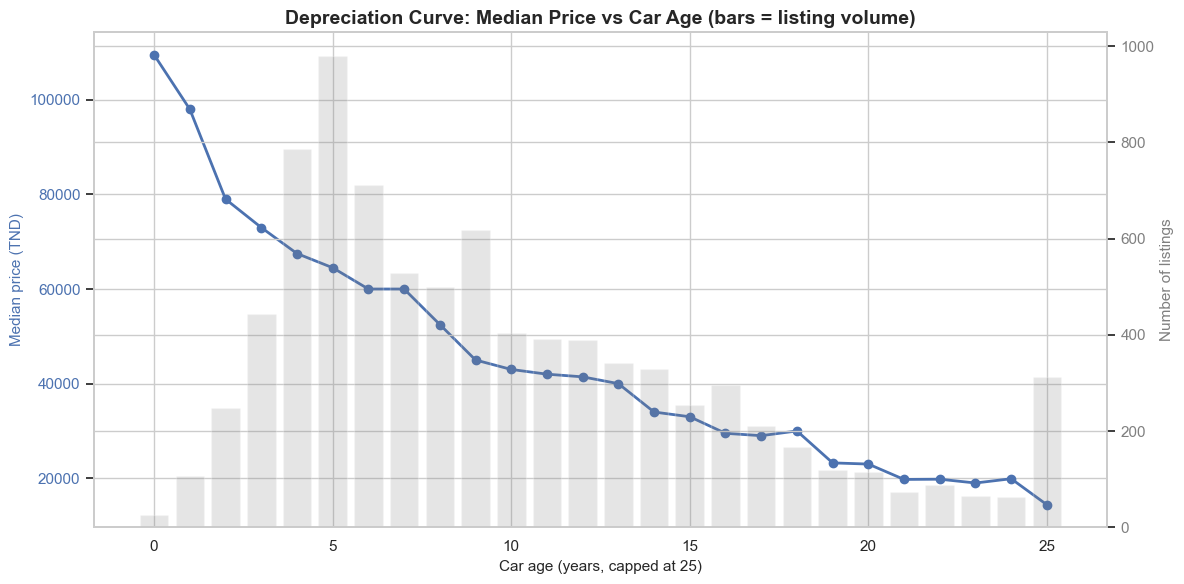

In [35]:
age_stats = (dfv.dropna(subset=['car_age'])
             .assign(car_age=lambda d: d['car_age'].clip(upper=25).round())
             .groupby('car_age')['price_tnd']
             .agg(['median', 'count']))
age_stats = age_stats[age_stats['count'] >= 5]  # drop very sparse ages

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(age_stats.index, age_stats['median'], marker='o', color='#4C72B0', linewidth=2, label='Median price')
ax1.set_xlabel('Car age (years, capped at 25)')
ax1.set_ylabel('Median price (TND)', color='#4C72B0')
ax1.tick_params(axis='y', labelcolor='#4C72B0')

ax2 = ax1.twinx()
ax2.bar(age_stats.index, age_stats['count'], alpha=0.2, color='gray', label='Number of listings')
ax2.set_ylabel('Number of listings', color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

plt.title('Depreciation Curve: Median Price vs Car Age (bars = listing volume)')
fig.tight_layout()
plt.show()


### 8.2 Listing activity over time

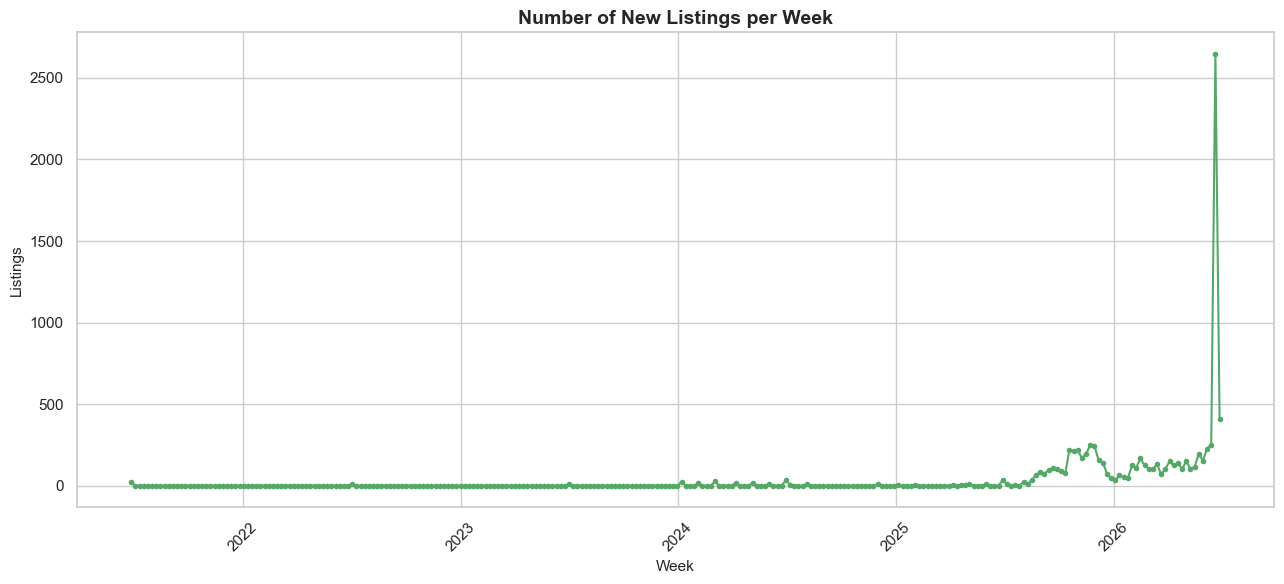

In [36]:
daily = dfc.dropna(subset=['listing_date']).set_index('listing_date').resample('W').size()

plt.figure(figsize=(13, 6))
plt.plot(daily.index, daily.values, marker='o', markersize=3, color='#55A868')
plt.title('Number of New Listings per Week')
plt.xlabel('Week')
plt.ylabel('Listings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 8.3 New vs. used: price gap per make

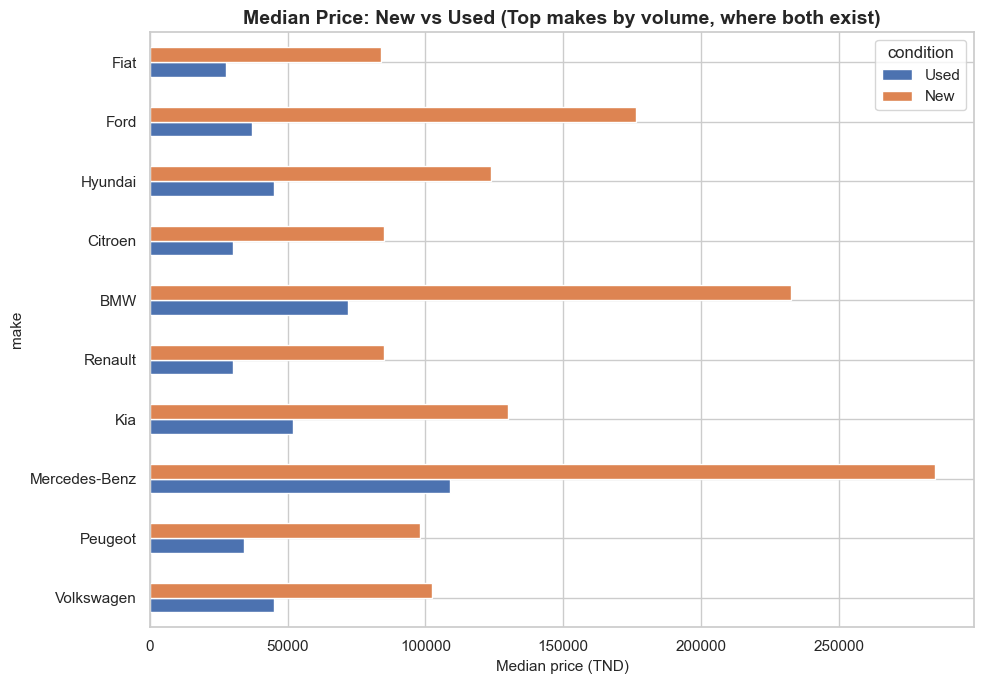

In [37]:
new_used = (dfv.groupby(['make', 'condition'])['price_tnd'].median()
            .unstack()
            .dropna()
            .assign(gap=lambda d: d.get('New', np.nan) - d.get('Used', np.nan)))

if 'New' in new_used.columns and 'Used' in new_used.columns:
    top_gap = new_used.reindex(dfc['make'].value_counts().index).dropna().head(10)
    top_gap[['Used', 'New']].plot(kind='barh', figsize=(10, 7), color=['#4C72B0', '#DD8452'])
    plt.title('Median Price: New vs Used (Top makes by volume, where both exist)')
    plt.xlabel('Median price (TND)')
    plt.tight_layout()
    plt.show()
else:
    print("Not enough New/Used overlap across makes to plot a meaningful comparison.")


### 8.4 "Deal quality" label distribution (`source_deal_label`)

Some sources tag listings with a fairness label (e.g. *Très bon prix*, *Prix élevé*). Let's
see the overall distribution — this is essentially a sentiment gauge on the market's pricing.


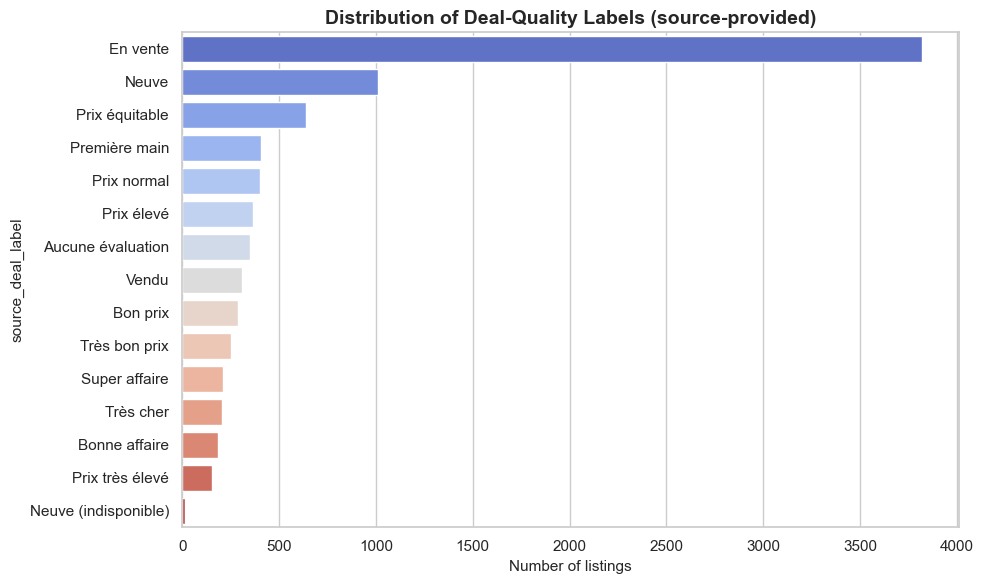

In [38]:
deal_counts = dfc['source_deal_label'].value_counts()

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=deal_counts.values, y=deal_counts.index, hue=deal_counts.index,
                  palette='coolwarm', legend=False)
ax.set_title('Distribution of Deal-Quality Labels (source-provided)')
ax.set_xlabel('Number of listings')
plt.tight_layout()
plt.show()


### 8.5 Price per km driven — which makes give the most "value" for high-mileage buyers?

`price_per_km` = price / (mileage + 1). Lower isn't always better (it can just mean an
old, cheap car), but it's an interesting relative-value lens across makes.


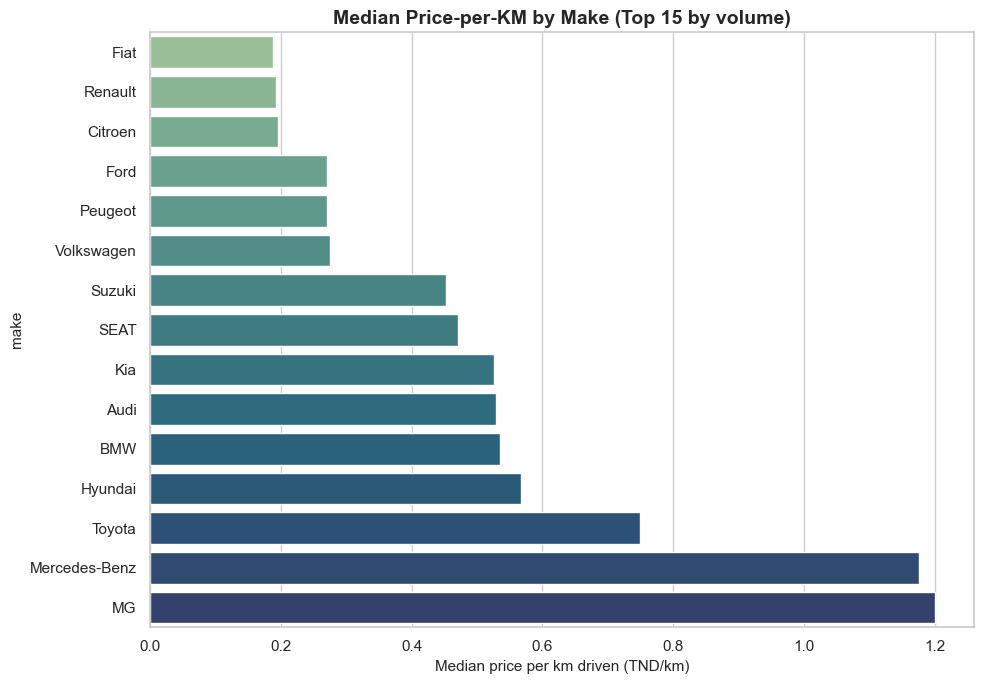

In [39]:
ppk = (dfv[dfv['make'].isin(top15_makes)]
       .groupby('make')['price_per_km'].median()
       .sort_values())

plt.figure(figsize=(10, 7))
ax = sns.barplot(x=ppk.values, y=ppk.index, hue=ppk.index, palette='crest', legend=False)
ax.set_title('Median Price-per-KM by Make (Top 15 by volume)')
ax.set_xlabel('Median price per km driven (TND/km)')
plt.tight_layout()
plt.show()


### 8.6 Private vs. Pro sellers — does pricing differ?

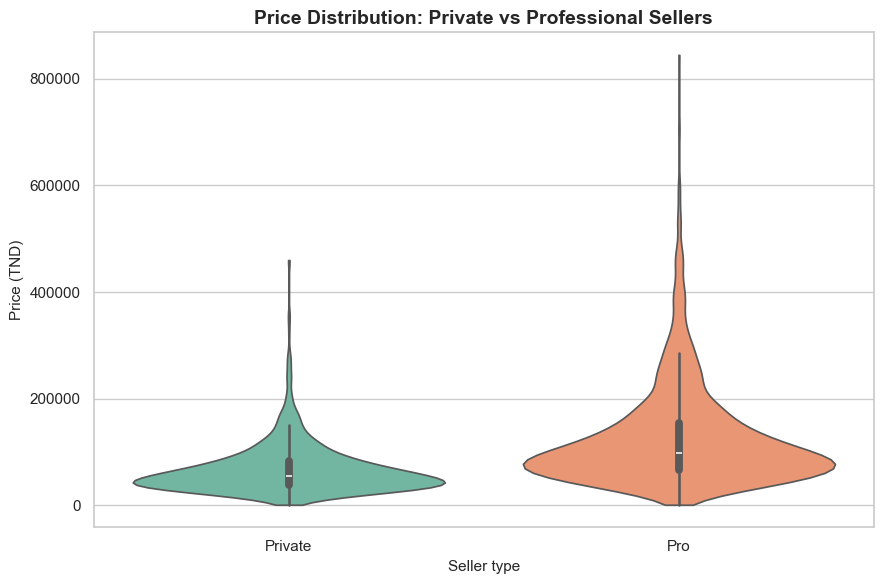

In [40]:
plt.figure(figsize=(9, 6))
sns.violinplot(data=dfv[dfv['seller_type'] != 'Unknown'], x='seller_type', y='price_tnd',
                hue='seller_type', palette='Set2', legend=False, cut=0)
plt.title('Price Distribution: Private vs Professional Sellers')
plt.xlabel('Seller type')
plt.ylabel('Price (TND)')
plt.tight_layout()
plt.show()


### 8.7 Regional price map (bar form) — where are cars most/least expensive?

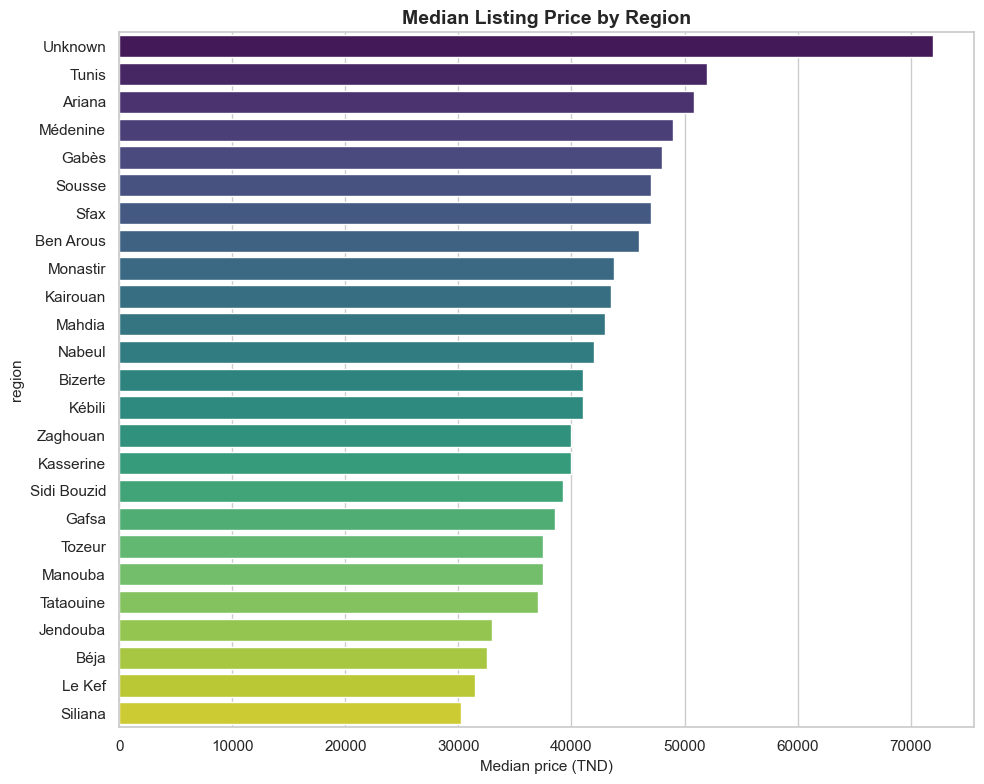

In [41]:
region_price = dfv.groupby('region')['price_tnd'].median().sort_values(ascending=False)

plt.figure(figsize=(10, 8))
ax = sns.barplot(x=region_price.values, y=region_price.index, hue=region_price.index,
                  palette='viridis', legend=False)
ax.set_title('Median Listing Price by Region')
ax.set_xlabel('Median price (TND)')
plt.tight_layout()
plt.show()


## 9. Summary of key findings

*(Auto-generated from the computations above — re-run the notebook and this will update.)*


In [42]:
print("="*70)
print("KEY FINDINGS SUMMARY")
print("="*70)

print(f"\n1. DATASET SIZE: {len(df):,} listings, {df.shape[1]} columns, from {df['source'].nunique()} sources.")

print(f"\n2. MISSING VALUES: worst columns are "
      f"{', '.join(missing[missing['n_missing']>0].index[:3].tolist())} "
      f"(see section 2 for full breakdown).")

print(f"\n3. DUPLICATES: {n_url_dupes:,} duplicate listing_url rows, "
      f"{n_near_dupes:,} likely near-duplicate listings (same make/model/year/price/mileage/region).")

print(f"\n4. OUTLIERS: dataset flags {dfc['is_price_outlier'].sum():,} price outliers and "
      f"{dfc['is_mileage_outlier'].sum():,} mileage outliers. Our own IQR check found "
      f"{n_price_excluded:,} rows with implausible prices and {n_mileage_excluded:,} with implausible mileage "
      f"(kept out of price/mileage visuals only).")

print(f"\n5. TOP MAKE: {make_counts.index[0]} ({make_counts.iloc[0]:,} listings), "
      f"followed by {make_counts.index[1]} and {make_counts.index[2]}.")

print(f"\n6. MOST COMMON FUEL TYPE: {dfc['fuel_type'].value_counts().index[0]} "
      f"({dfc['fuel_type'].value_counts().iloc[0]:,} listings).")

print(f"\n7. PRICE RANGE (plausible): median = {dfv['price_tnd'].median():,.0f} TND, "
      f"IQR = [{dfv['price_tnd'].quantile(.25):,.0f}, {dfv['price_tnd'].quantile(.75):,.0f}] TND.")

corr_age_price = dfv[['car_age','price_tnd']].dropna().corr().iloc[0,1]
print(f"\n8. CAR AGE vs PRICE correlation: {corr_age_price:.2f} "
      f"(negative, as expected -> older cars tend to be cheaper).")

print("\n" + "="*70)


KEY FINDINGS SUMMARY

1. DATASET SIZE: 10,927 listings, 20 columns, from 9 sources.

2. MISSING VALUES: worst columns are source_deal_label, listing_date, year (see section 2 for full breakdown).

3. DUPLICATES: 1,151 duplicate listing_url rows, 396 likely near-duplicate listings (same make/model/year/price/mileage/region).

4. OUTLIERS: dataset flags 60 price outliers and 71 mileage outliers. Our own IQR check found 479 rows with implausible prices and 184 with implausible mileage (kept out of price/mileage visuals only).

5. TOP MAKE: Volkswagen (1,213 listings), followed by Peugeot and Mercedes-Benz.

6. MOST COMMON FUEL TYPE: Petrol (7,119 listings).

7. PRICE RANGE (plausible): median = 50,000 TND, IQR = [33,450, 84,000] TND.

8. CAR AGE vs PRICE correlation: -0.40 (negative, as expected -> older cars tend to be cheaper).



---
### Suggested next steps
- **Modeling**: this dataset is a great candidate for a *price prediction* model
  (regression on `year`, `mileage_km`, `make`, `model`, `fuel_type`, `transmission`,
  `body_type`, `region`...). Target-encode high-cardinality columns like `model`.
- **Text mining**: `title_raw` likely contains extra info (trims, options like "AMG",
  "GTI", "4x4") not captured in structured columns — worth parsing with regex/NLP.
- **Geo analysis**: if lat/long or more granular location data becomes available, a real
  choropleth map of prices by governorate would be a nice upgrade over the regional bar chart.
- **De-duplication**: consider fuzzy-matching `title_raw` + `price_tnd` + `region` across
  sources to merge cross-posted listings into a single canonical record before deeper analysis.
